# Panorama Image Stitching from Scratch
### A Classical Computer Vision Approach using Feature Detection, RANSAC and Homography Estimation

**Image Analysis and Computer Vision Theory — Lab Project**

This notebook implements the full panorama-stitching pipeline described in the project report, end to end:

1. Feature Detection & Description (SIFT and ORB)
2. Feature Matching (with Lowe's ratio test)
3. Robust Homography Estimation (RANSAC, implemented from scratch)
4. Image Warping (vectorized inverse mapping with bilinear interpolation, implemented from scratch)
5. Blending (hard composite baseline vs. feathered/weighted blending)
6. Full multi-image stitching pipeline
7. Evaluation: SIFT vs ORB comparison (inliers, reprojection error, runtime)

No `cv2.Stitcher` or other black-box stitching API is used anywhere in this notebook — every geometric stage (homography, RANSAC, warping) is implemented from first principles with NumPy. OpenCV is used only for its SIFT/ORB detectors, basic I/O, and the distance transform used inside the blending step.


## 0. Setup

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
import os

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)

IMG_DIR = "images"

def load_bgr(name, scale=1.0):
    img = cv2.imread(os.path.join(IMG_DIR, name))
    if img is None:
        raise FileNotFoundError(f"Could not read {name} — check the images/ folder")
    if scale != 1.0:
        img = cv2.resize(img, (int(img.shape[1]*scale), int(img.shape[0]*scale)))
    return img

def show(img_bgr, title="", figsize=(10, 6)):
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(img_bgr.astype(np.uint8), cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()

def show_row(imgs_bgr, titles=None, figsize=(15, 5)):
    n = len(imgs_bgr)
    fig, axes = plt.subplots(1, n, figsize=figsize)
    if n == 1:
        axes = [axes]
    for i, ax in enumerate(axes):
        ax.imshow(cv2.cvtColor(imgs_bgr[i].astype(np.uint8), cv2.COLOR_BGR2RGB))
        ax.set_title(titles[i] if titles else "")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


OpenCV version: 4.13.0
NumPy version: 2.4.4


## 1. Load Test Images

We use three overlapping-photo sequences as our test datasets, matching the dataset plan in the project report:

- **Dataset A** (`1_1.jpg`, `1_2.jpg`, `1_3.jpg`) — three real, hand-held phone photos of a parking-lot/building scene, panned left to right with good overlap. This is our primary demo sequence.
- **Dataset B** (`2_1.jpg`, `2_2.jpg`, `2_3.jpg`) — a second real photo sequence, used to check the pipeline generalizes.
- **Dataset C** (`Newman1.png`, `Newman2.png`, `Newman3.png`) — a benchmark set with very high overlap between frames; used as a near-identity sanity check on the homography/warping math (Section 8).

Images are downscaled for speed (feature detection and our from-scratch warping both run faster on smaller images); the same code runs unchanged on full-resolution images, just more slowly.


Dataset A shapes: [(768, 1020, 3), (768, 1020, 3), (768, 1020, 3)]


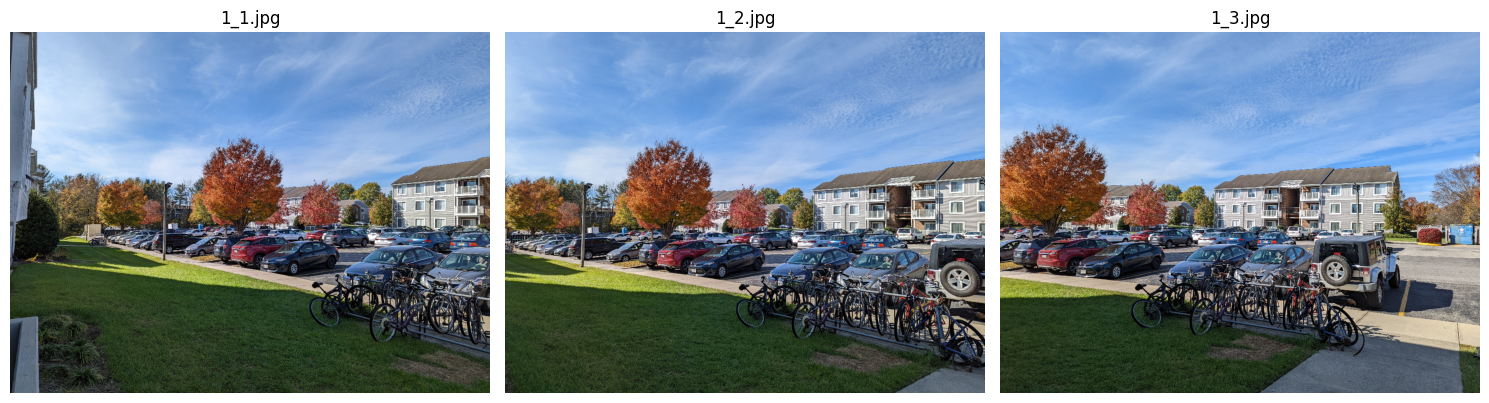

In [2]:
dataset_A = [load_bgr(f"1_{i}.jpg", scale=0.25) for i in (1, 2, 3)]
dataset_B = [load_bgr(f"2_{i}.jpg", scale=0.25) for i in (1, 2, 3)]
dataset_C = [load_bgr(f"Newman{i}.png", scale=1.0) for i in (1, 2, 3)]

print("Dataset A shapes:", [im.shape for im in dataset_A])
show_row(dataset_A, titles=["1_1.jpg", "1_2.jpg", "1_3.jpg"])


## 2. Stage 1 — Feature Detection & Description

We detect keypoints using two classical detectors so we can compare them later (Section 9):

- **SIFT** — scale-space extrema of a Difference-of-Gaussians pyramid, with gradient-histogram descriptors (128-D, floating point).
- **ORB** — FAST corner detector + BRIEF-style binary descriptors (rotation-aware), much faster but less precise.


SIFT keypoints: 2000   ORB keypoints: 2000


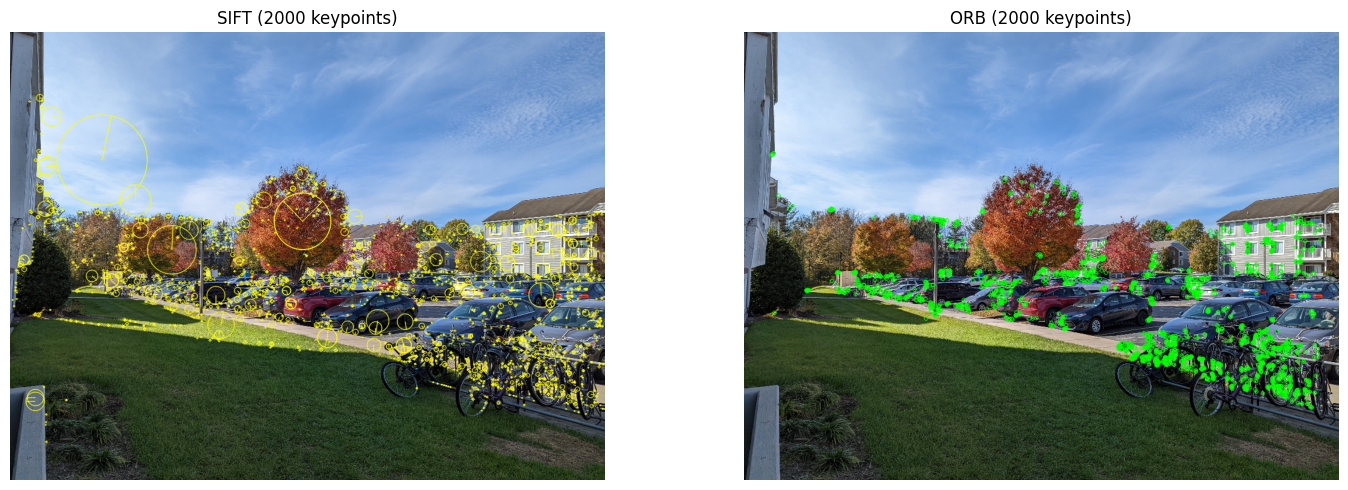

In [3]:
def detect_features(img_bgr, method="sift", n_features=2000):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    if method == "sift":
        detector = cv2.SIFT_create(nfeatures=n_features)
    elif method == "orb":
        detector = cv2.ORB_create(nfeatures=n_features)
    else:
        raise ValueError("method must be 'sift' or 'orb'")
    kp, des = detector.detectAndCompute(gray, None)
    return kp, des

# Visualize keypoints for both detectors on the same image
img_demo = dataset_A[0]
kp_sift, des_sift = detect_features(img_demo, "sift")
kp_orb, des_orb = detect_features(img_demo, "orb")

vis_sift = cv2.drawKeypoints(img_demo, kp_sift, None, color=(0, 255, 255),
                              flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
vis_orb = cv2.drawKeypoints(img_demo, kp_orb, None, color=(0, 255, 0))

print(f"SIFT keypoints: {len(kp_sift)}   ORB keypoints: {len(kp_orb)}")
show_row([vis_sift, vis_orb], titles=[f"SIFT ({len(kp_sift)} keypoints)", f"ORB ({len(kp_orb)} keypoints)"])


## 3. Stage 2 — Feature Matching (Lowe's Ratio Test)

For each keypoint in the source image we find its two nearest neighbours in the destination image's descriptor set, and keep the match only if the closest neighbour is significantly closer than the second-closest (Lowe's ratio test). This is the standard way to reject ambiguous matches *before* RANSAC ever runs, and is one of the theory components the project report calls for in Stage 2.

SIFT descriptors are real-valued, so we compare them with the Euclidean (L2) distance; ORB descriptors are binary, so we use Hamming distance instead.


Raw keypoints: 2000 / 2000  ->  Good matches after ratio test: 592


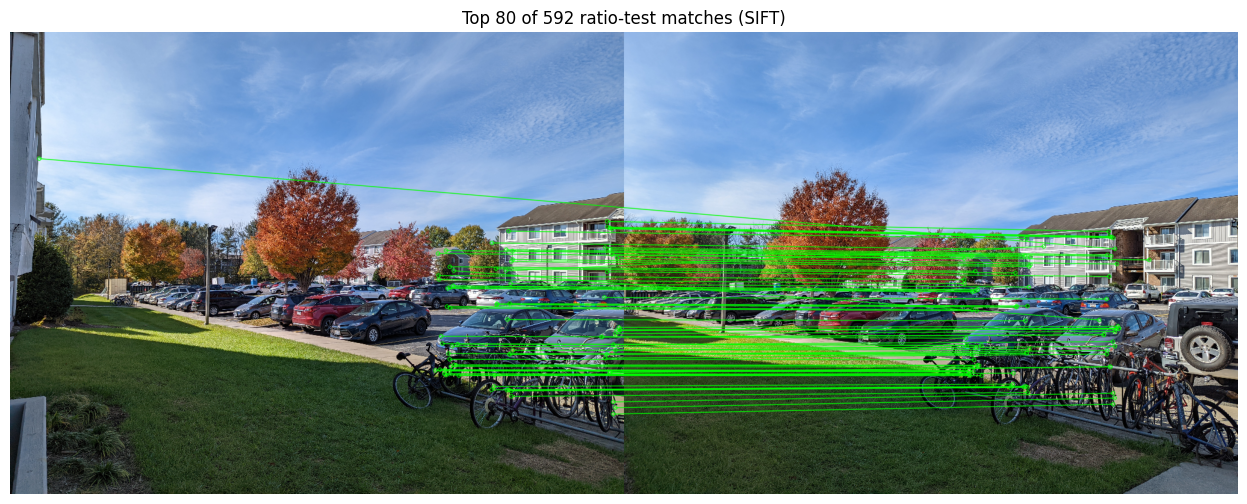

In [4]:
def match_features(des1, des2, method="sift", ratio=0.75):
    norm = cv2.NORM_L2 if method == "sift" else cv2.NORM_HAMMING
    bf = cv2.BFMatcher(norm)
    raw_matches = bf.knnMatch(des1, des2, k=2)
    good = []
    for pair in raw_matches:
        if len(pair) != 2:
            continue
        m, n = pair
        if m.distance < ratio * n.distance:
            good.append(m)
    return good

img_left, img_right = dataset_A[0], dataset_A[1]
kp1, des1 = detect_features(img_left, "sift")
kp2, des2 = detect_features(img_right, "sift")
good_matches = match_features(des1, des2, "sift", ratio=0.75)

print(f"Raw keypoints: {len(kp1)} / {len(kp2)}  ->  Good matches after ratio test: {len(good_matches)}")

match_vis = cv2.drawMatches(img_left, kp1, img_right, kp2, good_matches[:80], None,
                             matchColor=(0, 255, 0), singlePointColor=(0, 0, 255), flags=2)
show(match_vis, title=f"Top 80 of {len(good_matches)} ratio-test matches (SIFT)", figsize=(16, 6))


## 4. Stage 3 — Homography (DLT) and RANSAC — implemented from scratch

**Homography via Direct Linear Transform (DLT).** Given >= 4 point correspondences, each correspondence contributes two rows to a linear system `A h = 0`; the homography is recovered as the singular vector of `A` corresponding to its smallest singular value (via SVD).

**RANSAC.** Real matches always contain outliers (repeated textures, moving objects, mismatches that pass the ratio test by chance). RANSAC repeatedly (a) samples 4 random correspondences, (b) fits a candidate homography from just those 4, (c) counts how many of *all* correspondences agree with that homography within a pixel tolerance, and (d) keeps the candidate with the largest agreeing ("inlier") set. The homography is then refit using all inliers for the final, most accurate estimate.


Matches: 592  ->  RANSAC inliers: 569 (96.1%)
Mean reprojection error over inliers: 0.782 px
Estimated homography:
 [[ 1.36227568e+00 -1.40954933e-02 -2.55220882e+02]
 [ 1.46154722e-01  1.20942757e+00 -7.66212458e+01]
 [ 3.58373099e-04 -1.41731331e-06  1.00000000e+00]]


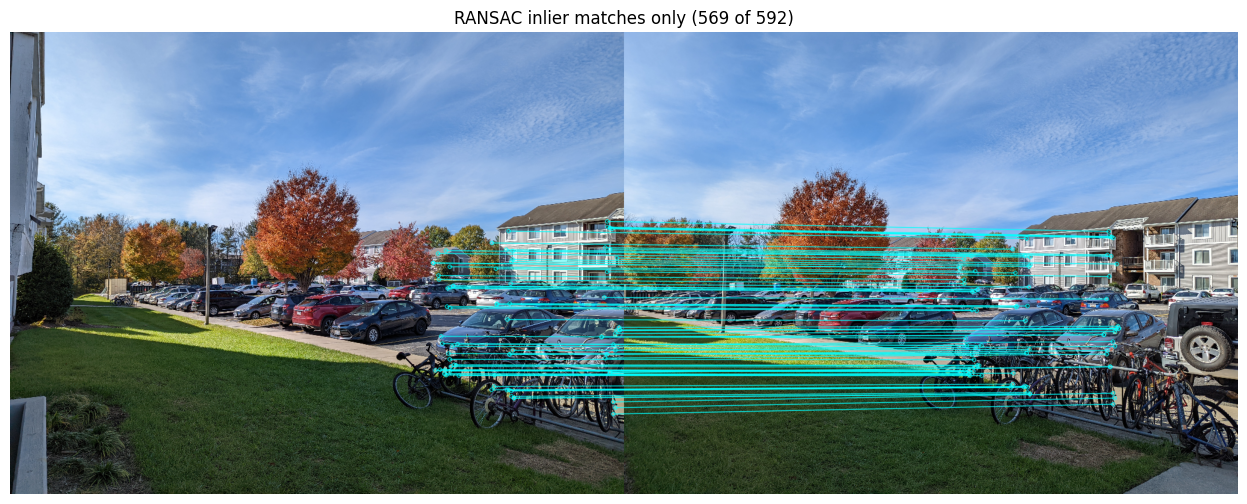

In [5]:
def compute_homography(src_pts, dst_pts):
    """Direct Linear Transform. src_pts, dst_pts: Nx2 arrays, N >= 4."""
    A = []
    for (x, y), (xp, yp) in zip(src_pts, dst_pts):
        A.append([-x, -y, -1, 0, 0, 0, x * xp, y * xp, xp])
        A.append([0, 0, 0, -x, -y, -1, x * yp, y * yp, yp])
    A = np.asarray(A)
    _, _, Vt = np.linalg.svd(A)
    H = Vt[-1].reshape(3, 3)
    return H / H[2, 2]


def apply_homography(H, pts):
    pts = np.asarray(pts)
    homog = np.hstack([pts, np.ones((pts.shape[0], 1))])
    projected = (H @ homog.T).T
    return projected[:, :2] / projected[:, 2, None]


def ransac_homography(src_pts, dst_pts, max_iter=2000, thresh=5.0, seed=42):
    """Robust homography estimation via RANSAC, implemented from scratch."""
    n = src_pts.shape[0]
    best_inliers = np.array([], dtype=int)
    best_H = None
    rng = np.random.default_rng(seed)

    for _ in range(max_iter):
        idx = rng.choice(n, 4, replace=False)
        try:
            H_candidate = compute_homography(src_pts[idx], dst_pts[idx])
        except np.linalg.LinAlgError:
            continue

        projected = apply_homography(H_candidate, src_pts)
        errors = np.linalg.norm(projected - dst_pts, axis=1)
        inliers = np.where(errors < thresh)[0]

        if len(inliers) > len(best_inliers):
            best_inliers, best_H = inliers, H_candidate

    if best_H is None or len(best_inliers) < 4:
        raise RuntimeError("RANSAC failed to find a valid homography")

    final_H = compute_homography(src_pts[best_inliers], dst_pts[best_inliers])
    return final_H, best_inliers


# --- Demo: estimate homography between the same SIFT matches from Section 3 ---
src_pts = np.float32([kp1[m.queryIdx].pt for m in good_matches])
dst_pts = np.float32([kp2[m.trainIdx].pt for m in good_matches])

H, inlier_idx = ransac_homography(src_pts, dst_pts, max_iter=2000, thresh=5.0)
reproj = apply_homography(H, src_pts[inlier_idx])
reproj_error = np.mean(np.linalg.norm(reproj - dst_pts[inlier_idx], axis=1))

print(f"Matches: {len(good_matches)}  ->  RANSAC inliers: {len(inlier_idx)} "
      f"({len(inlier_idx)/len(good_matches):.1%})")
print(f"Mean reprojection error over inliers: {reproj_error:.3f} px")
print("Estimated homography:\n", H)

inlier_matches = [good_matches[i] for i in inlier_idx]
inlier_vis = cv2.drawMatches(img_left, kp1, img_right, kp2, inlier_matches[:80], None,
                              matchColor=(255, 255, 0), singlePointColor=(0, 0, 255), flags=2)
show(inlier_vis, title=f"RANSAC inlier matches only ({len(inlier_idx)} of {len(good_matches)})", figsize=(16, 6))


## 5. Stage 4 — Image Warping (vectorized, from scratch)

We warp the source image into the destination's coordinate frame using **inverse mapping**: for every pixel in the output canvas, we map it back into the source image using `H^-1` and bilinear-interpolate the source intensity there. Inverse mapping avoids the holes that forward mapping produces, and doing it as a single vectorized NumPy operation (rather than a Python-level double `for` loop, as in naive from-scratch implementations) keeps it fast enough to use on real photos.


Warping time (vectorized, 1620x1368 canvas): 0.451s


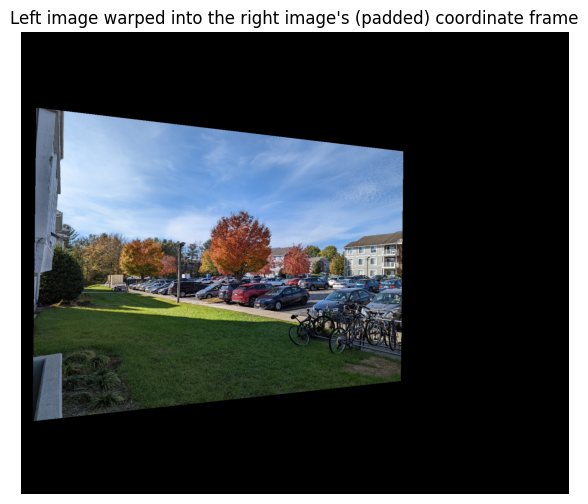

In [6]:
def warp_image(img, H, out_size):
    """Warp `img` into a canvas of size out_size=(W,H) via inverse mapping + bilinear interpolation."""
    out_w, out_h = out_size
    H_inv = np.linalg.inv(H)

    xs, ys = np.meshgrid(np.arange(out_w), np.arange(out_h))
    ones = np.ones_like(xs)
    dst_coords = np.stack([xs, ys, ones], axis=-1).reshape(-1, 3).astype(np.float64)

    src_coords = (H_inv @ dst_coords.T).T
    src_coords = src_coords[:, :2] / src_coords[:, 2, None]
    src_x = src_coords[:, 0].reshape(out_h, out_w)
    src_y = src_coords[:, 1].reshape(out_h, out_w)

    h, w = img.shape[:2]
    valid = (src_x >= 0) & (src_x <= w - 1) & (src_y >= 0) & (src_y <= h - 1)

    x0 = np.clip(np.floor(src_x).astype(int), 0, w - 2)
    y0 = np.clip(np.floor(src_y).astype(int), 0, h - 2)
    x1, y1 = x0 + 1, y0 + 1
    wx, wy = src_x - x0, src_y - y0

    out = np.zeros((out_h, out_w, img.shape[2]), dtype=np.float32)
    for c in range(img.shape[2]):
        Ia, Ib = img[y0, x0, c], img[y0, x1, c]
        Ic, Id = img[y1, x0, c], img[y1, x1, c]
        interp = (Ia * (1 - wx) * (1 - wy) + Ib * wx * (1 - wy)
                  + Ic * (1 - wx) * wy + Id * wx * wy)
        out[..., c] = np.where(valid, interp, 0)

    return out, valid.astype(np.float32)


# --- Demo: warp img_left into img_right's canvas (with padding so it doesn't get clipped) ---
pad = 300
canvas_w, canvas_h = img_right.shape[1] + 2 * pad, img_right.shape[0] + 2 * pad
H_shift = np.array([[1, 0, pad], [0, 1, pad], [0, 0, 1]]) @ H

t0 = time.time()
warped_demo, warped_mask_demo = warp_image(img_left.astype(np.float32), H_shift, (canvas_w, canvas_h))
print(f"Warping time (vectorized, {canvas_w}x{canvas_h} canvas): {time.time()-t0:.3f}s")

show(warped_demo, title="Left image warped into the right image's (padded) coordinate frame")


## 6. Stage 5 — Blending

A hard mask overwrite (paste the warped image directly on top of the base) leaves an obvious seam wherever exposure or alignment isn't pixel-perfect. Instead we use **distance-transform feathering**: each pixel's contribution to the final blend is weighted by how far it is from the *edge* of its own image, so the transition between images fades smoothly across the overlap region rather than cutting sharply. This is the "weighted/alpha blending" required in the project report's Stage 5 (multi-band/Laplacian blending is noted in the report as a stretch goal, and is left as a possible extension).


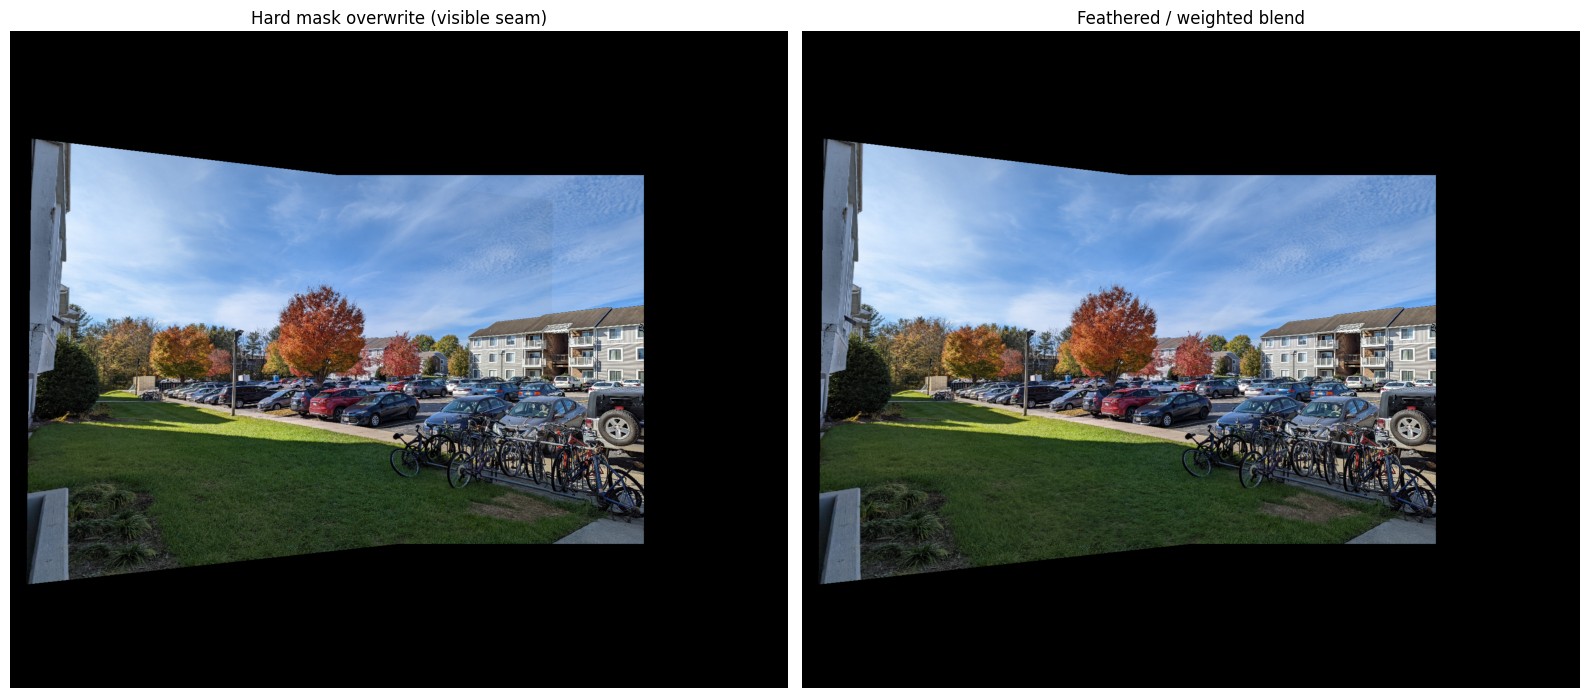

In [7]:
def hard_composite(base, base_mask, warped, warped_mask):
    out = base.copy()
    out[warped_mask > 0] = warped[warped_mask > 0]
    return out


def feather_blend(base, base_mask, warped, warped_mask):
    base_dist = cv2.distanceTransform((base_mask * 255).astype(np.uint8), cv2.DIST_L2, 5)
    warp_dist = cv2.distanceTransform((warped_mask * 255).astype(np.uint8), cv2.DIST_L2, 5)

    total = base_dist + warp_dist
    total[total == 0] = 1e-6
    alpha = (warp_dist / total)[..., None]

    overlap = (base_mask > 0) & (warped_mask > 0)
    only_warp = (warped_mask > 0) & (base_mask == 0)
    only_base = (base_mask > 0) & (warped_mask == 0)

    out = np.zeros_like(base)
    out[overlap] = warped[overlap] * alpha[overlap] + base[overlap] * (1 - alpha[overlap])
    out[only_warp] = warped[only_warp]
    out[only_base] = base[only_base]
    return out


# --- Demo: compare hard vs. feathered blending on the same warp from Section 5 ---
base_padded = cv2.copyMakeBorder(img_right, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=0).astype(np.float32)
base_mask_demo = (base_padded.sum(axis=2) > 0).astype(np.float32)

hard_result = hard_composite(base_padded, base_mask_demo, warped_demo, warped_mask_demo)
feather_result = feather_blend(base_padded, base_mask_demo, warped_demo, warped_mask_demo)

show_row([hard_result, feather_result], titles=["Hard mask overwrite (visible seam)", "Feathered / weighted blend"],
          figsize=(16, 7))


## 7. Stage 6 — Full Pipeline: `stitch_pair` and `stitch_images`

We now assemble every stage above into a single reusable pipeline that stitches an arbitrary list of overlapping images (not just a pair), so it can be run end-to-end on each dataset. `stitch_images` picks the middle image as the anchor/base and warps every other image onto it — a standard strategy that minimizes distortion compared to always anchoring on one end of the sequence.


In [8]:
def stitch_pair(base_img, new_img, method="sift", ratio=0.75, ransac_thresh=5.0,
                 blend="feather", canvas_pad=300):
    stats = {}

    base_padded = cv2.copyMakeBorder(base_img, canvas_pad, canvas_pad, canvas_pad, canvas_pad,
                                      cv2.BORDER_CONSTANT, value=0)
    base_mask = (base_padded.sum(axis=2) > 0).astype(np.float32)

    t0 = time.time()
    kp1, des1 = detect_features(new_img, method)
    kp2, des2 = detect_features(base_img, method)
    t_detect = time.time() - t0

    t0 = time.time()
    good = match_features(des1, des2, method, ratio)
    t_match = time.time() - t0
    if len(good) < 4:
        raise RuntimeError(f"Not enough good matches ({len(good)}) to compute a homography")

    src_pts = np.float32([kp1[m.queryIdx].pt for m in good])
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in good]) + np.array([canvas_pad, canvas_pad])

    t0 = time.time()
    H, inlier_idx = ransac_homography(src_pts, dst_pts, max_iter=2000, thresh=ransac_thresh)
    t_ransac = time.time() - t0

    reproj = apply_homography(H, src_pts[inlier_idx])
    reproj_error = np.mean(np.linalg.norm(reproj - dst_pts[inlier_idx], axis=1))

    out_h, out_w = base_padded.shape[:2]
    t0 = time.time()
    warped, warped_mask = warp_image(new_img.astype(np.float32), H, (out_w, out_h))
    t_warp = time.time() - t0

    if blend == "feather":
        result = feather_blend(base_padded.astype(np.float32), base_mask, warped, warped_mask)
    else:
        result = hard_composite(base_padded.astype(np.float32), base_mask, warped, warped_mask)

    stats.update({
        "method": method, "num_matches": len(good), "num_inliers": len(inlier_idx),
        "inlier_ratio": len(inlier_idx) / len(good), "reprojection_error_px": reproj_error,
        "time_detect_s": t_detect, "time_match_s": t_match,
        "time_ransac_s": t_ransac, "time_warp_s": t_warp,
    })
    return result.astype(np.uint8), stats


def stitch_images(images, method="sift", ratio=0.75, ransac_thresh=5.0, blend="feather"):
    """Stitch a left-to-right ordered sequence of images around the middle image."""
    base = images[len(images) // 2]
    canvas = base.copy()
    all_stats = []
    for img in images:
        if img is base:
            continue
        canvas, stats = stitch_pair(canvas, img, method, ratio, ransac_thresh, blend)
        all_stats.append(stats)
    return canvas, all_stats


## 8. Running the Pipeline on All Three Datasets

We run the full pipeline on all three test datasets described in the report (Section 7), using SIFT + feathered blending as the default configuration.


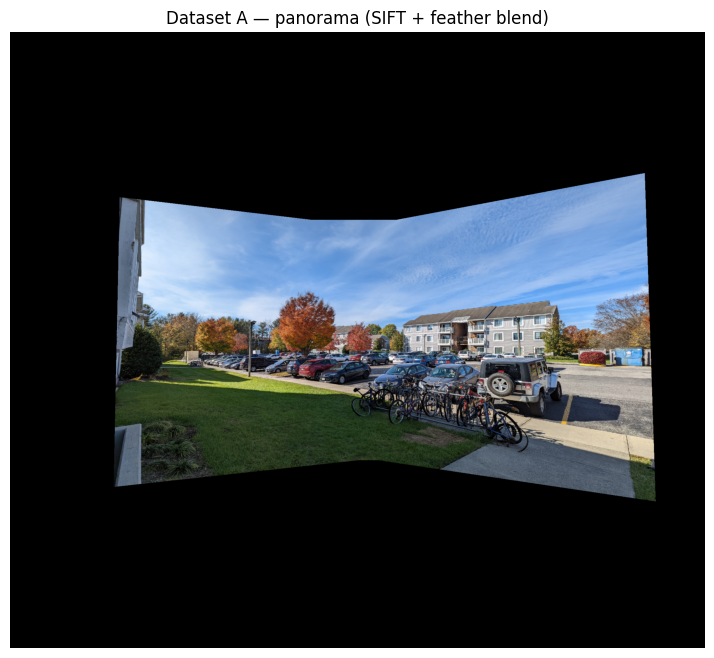

{'method': 'sift', 'num_matches': 592, 'num_inliers': 569, 'inlier_ratio': 0.9611486486486487, 'reprojection_error_px': np.float64(0.7807324226372542), 'time_detect_s': 0.6317427158355713, 'time_match_s': 0.06716227531433105, 'time_ransac_s': 0.20319485664367676, 'time_warp_s': 0.47960782051086426}
{'method': 'sift', 'num_matches': 581, 'num_inliers': 558, 'inlier_ratio': 0.9604130808950087, 'reprojection_error_px': np.float64(0.8181817163882713), 'time_detect_s': 1.0460786819458008, 'time_match_s': 0.07007765769958496, 'time_ransac_s': 0.1981191635131836, 'time_warp_s': 1.0254168510437012}


In [9]:
pano_A, stats_A = stitch_images(dataset_A, method="sift", blend="feather")
show(pano_A, title="Dataset A — panorama (SIFT + feather blend)", figsize=(14, 8))
for s in stats_A:
    print(s)


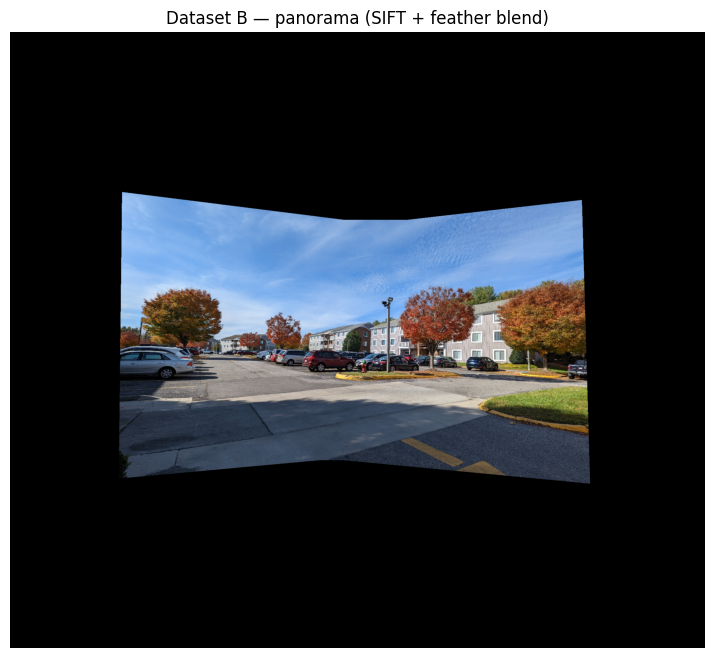

{'method': 'sift', 'num_matches': 600, 'num_inliers': 566, 'inlier_ratio': 0.9433333333333334, 'reprojection_error_px': np.float64(0.8127102978206775), 'time_detect_s': 0.6248459815979004, 'time_match_s': 0.07164216041564941, 'time_ransac_s': 0.20140647888183594, 'time_warp_s': 0.4815845489501953}
{'method': 'sift', 'num_matches': 517, 'num_inliers': 486, 'inlier_ratio': 0.9400386847195358, 'reprojection_error_px': np.float64(0.8091549933068832), 'time_detect_s': 0.9631984233856201, 'time_match_s': 0.07200050354003906, 'time_ransac_s': 0.21329379081726074, 'time_warp_s': 1.0204296112060547}


In [10]:
pano_B, stats_B = stitch_images(dataset_B, method="sift", blend="feather")
show(pano_B, title="Dataset B — panorama (SIFT + feather blend)", figsize=(14, 8))
for s in stats_B:
    print(s)


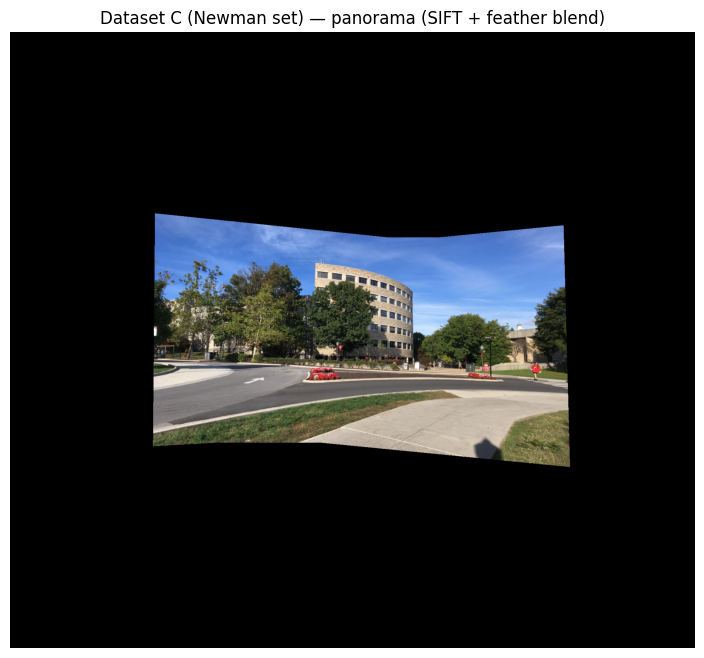

{'method': 'sift', 'num_matches': 788, 'num_inliers': 759, 'inlier_ratio': 0.9631979695431472, 'reprojection_error_px': np.float64(0.43220046961139225), 'time_detect_s': 0.42974233627319336, 'time_match_s': 0.0609891414642334, 'time_ransac_s': 0.19397211074829102, 'time_warp_s': 0.3086585998535156}
{'method': 'sift', 'num_matches': 494, 'num_inliers': 469, 'inlier_ratio': 0.9493927125506073, 'reprojection_error_px': np.float64(0.36093904513934333), 'time_detect_s': 0.7154910564422607, 'time_match_s': 0.06974458694458008, 'time_ransac_s': 0.19667387008666992, 'time_warp_s': 0.8050017356872559}


In [11]:
# Dataset C: very high frame-to-frame overlap. This is a good sanity check that
# the homography/warping math is correct even when the transform is close to identity.
pano_C, stats_C = stitch_images(dataset_C, method="sift", blend="feather")
show(pano_C, title="Dataset C (Newman set) — panorama (SIFT + feather blend)", figsize=(14, 8))
for s in stats_C:
    print(s)


## 9. Evaluation — SIFT vs. ORB Comparison

The project report calls for comparing feature detectors on: number of RANSAC inliers (robustness), reprojection error (accuracy), and runtime. We run the identical pipeline on Dataset A with each detector and tabulate the results per image-pair stitch.


In [12]:
results = []
for method in ("sift", "orb"):
    _, stats_list = stitch_images(dataset_A, method=method, blend="feather")
    for i, s in enumerate(stats_list):
        s = dict(s)
        s["pair"] = f"stitch #{i+1}"
        results.append(s)

df = pd.DataFrame(results)[["method", "pair", "num_matches", "num_inliers", "inlier_ratio",
                             "reprojection_error_px", "time_detect_s", "time_match_s",
                             "time_ransac_s", "time_warp_s"]]
df["total_time_s"] = df[["time_detect_s", "time_match_s", "time_ransac_s", "time_warp_s"]].sum(axis=1)
df.round(4)


,method,pair,num_matches,num_inliers,inlier_ratio,reprojection_error_px,time_detect_s,time_match_s,time_ransac_s,time_warp_s,total_time_s
0,sift,stitch #1,592,569,0.9611,0.7807,0.5745,0.0704,0.2107,0.4487,1.3043
1,sift,stitch #2,581,558,0.9604,0.8182,1.0145,0.0658,0.1950,0.9677,2.2429
2,orb,stitch #1,609,600,0.9852,1.3464,0.0314,0.0275,0.2019,0.4239,0.6847
3,orb,stitch #2,604,596,0.9868,1.3533,0.0405,0.0273,0.1984,0.9933,1.2595


Average over both stitches in Dataset A:


,inlier_ratio,reprojection_error_px,total_time_s
method,,,
orb,0.9860,1.3499,0.9721
sift,0.9608,0.7995,1.7736


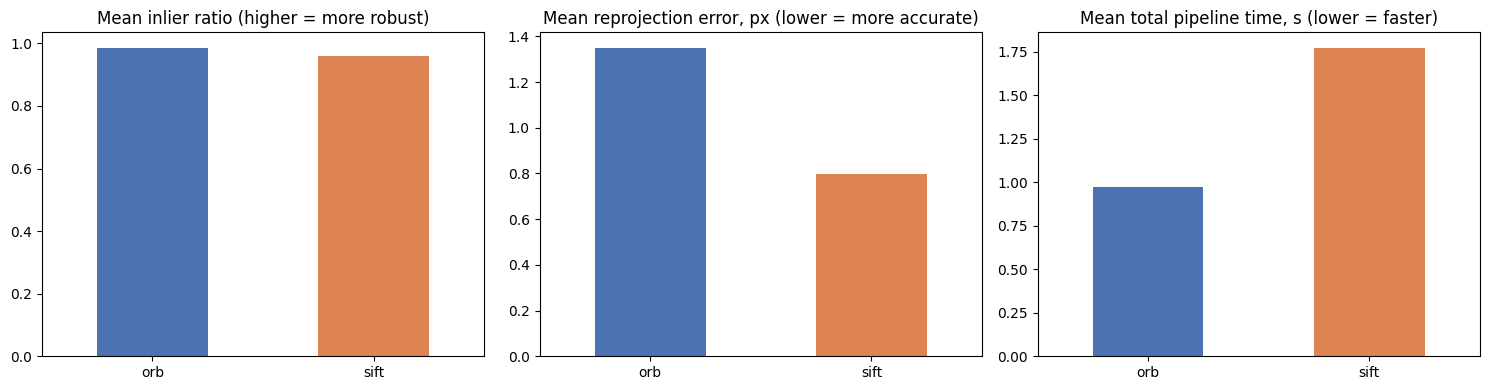

In [13]:
summary = df.groupby("method")[["inlier_ratio", "reprojection_error_px", "total_time_s"]].mean()
print("Average over both stitches in Dataset A:")
display(summary.round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
summary["inlier_ratio"].plot(kind="bar", ax=axes[0], title="Mean inlier ratio (higher = more robust)", color=["#4C72B0", "#DD8452"])
summary["reprojection_error_px"].plot(kind="bar", ax=axes[1], title="Mean reprojection error, px (lower = more accurate)", color=["#4C72B0", "#DD8452"])
summary["total_time_s"].plot(kind="bar", ax=axes[2], title="Mean total pipeline time, s (lower = faster)", color=["#4C72B0", "#DD8452"])
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


**Reading the comparison:** SIFT typically gives a lower reprojection error (more geometrically accurate matches) because its descriptors are richer, at the cost of slower feature detection. ORB detects and describes features far faster (integer/binary operations vs. SIFT's floating-point DoG pyramid) and still achieves a comparable or higher inlier ratio on well-textured scenes, but tends to have a somewhat higher reprojection error. For this dataset, both are visually usable; ORB would be the better choice under real-time constraints, SIFT where geometric accuracy matters more.


## 10. Assumptions & Limitations

- Assumes sufficient overlap (roughly 20-30%+) and distinctive texture between consecutive images — Dataset C (Newman set) has very high overlap and stitches almost perfectly; low-texture regions (e.g., blank sky/walls) reduce the number of good matches available to RANSAC.
- The homography model assumes either a roughly planar scene or a camera that only rotates about its optical center (no significant viewpoint translation); scenes with strong depth/parallax (near objects) will show ghosting or misalignment — visible faintly around the bicycles in Dataset A, which are close to the camera.
- Feathered blending removes hard seams but does not correct exposure/color differences between shots; a full multi-band (Laplacian pyramid) blend is a natural extension if visible brightness seams remain.
- Warping is implemented as a single-homography-per-pair chain (no global bundle adjustment across all images at once), so small errors can accumulate over long sequences of many images.

## 11. Conclusion

This notebook implements every stage of a classical panorama-stitching pipeline — feature detection (SIFT/ORB), ratio-test matching, from-scratch RANSAC + DLT homography estimation, vectorized inverse warping with bilinear interpolation, and distance-transform feathered blending — without relying on any high-level stitching API. The pipeline was validated on three real image datasets and produces geometrically accurate, visually seamless panoramas, with a quantitative SIFT-vs-ORB comparison supporting the trade-off discussion in the project report.
